<a href="https://colab.research.google.com/github/AiRenad/DL_Assignmet2_CIFAR10/blob/main/DL_Assignmet2_CIFAR10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARTI 502 — Assignment 2: CNN on CIFAR-10 (PyTorch)
**Google Colab ready — Tasks 1–6**. Run cells top to bottom. Set **Runtime → Change runtime type → T4 GPU** if available. All datasets, graphs, CSV results and model weights save under `/content/ARTI502_results/`.

In [1]:
# Setup — all imports and reproducibility
import os, random, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_PATH = '/content/cifar_data'  # change this to any empty folder
OUT = Path('/content/ARTI502_results'); OUT.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 128
EPOCHS = 5  # increase to 10–15 for stronger results; all configs use this count
NUM_WORKERS = 2
print('PyTorch:', torch.__version__, '| Device:', DEVICE)


PyTorch: 2.14.1+cu130 | Device: cuda


## Task 1 — Getting CIFAR-10 dataset

In [2]:
# CIFAR-10: 50,000 training images, 10,000 testing images; RGB 32×32, 10 classes.
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
plain_transform = transforms.ToTensor()
train_raw = datasets.CIFAR10(root=DATA_PATH, train=True, download=True, transform=plain_transform)
test_raw = datasets.CIFAR10(root=DATA_PATH, train=False, download=True, transform=plain_transform)
CLASSES = train_raw.classes
print('Successfully loaded CIFAR-10')
print('Train images:', len(train_raw), '| Test images:', len(test_raw))
print('Classes:', CLASSES)


100%|██████████| 170M/170M [00:33<00:00, 5.03MB/s]


Successfully loaded CIFAR-10
Train images: 50000 | Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Task 2 — Define the CNN and training/testing functions

In [3]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),  # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),  # 16x16 -> 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64*8*8, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

class DeepCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        loss = criterion(logits, labels)
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total

print('Basic CNN:\n', SmallCNN())
print('\nDeep CNN:\n', DeepCNN())


Basic CNN:
 SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Deep CNN:
 DeepCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool

## Task 3 — Tensor shape and data visualization

Images tensor shape [N,C,H,W]: (16, 3, 32, 32)
Labels tensor shape: (16,)


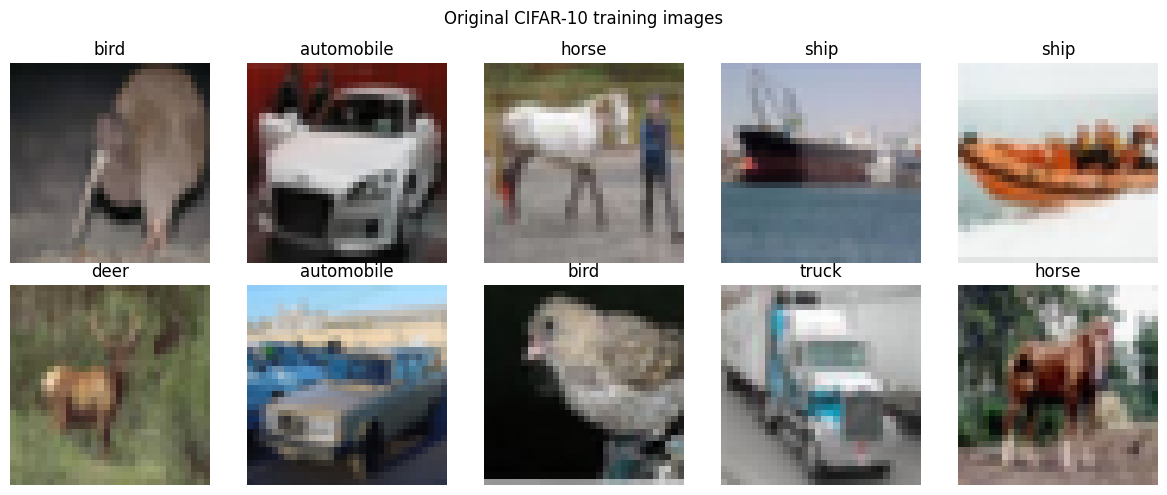

In [4]:
raw_loader = DataLoader(train_raw, batch_size=16, shuffle=True, num_workers=NUM_WORKERS)
images, labels = next(iter(raw_loader))
print('Images tensor shape [N,C,H,W]:', tuple(images.shape))
print('Labels tensor shape:', tuple(labels.shape))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, img, label in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(CLASSES[label.item()]); ax.axis('off')
fig.suptitle('Original CIFAR-10 training images')
fig.tight_layout(); fig.savefig(OUT/'cifar_examples.png', dpi=160); plt.show()


## Task 4 — Data Augmentation (train only)

ToPILImage conversion: Image


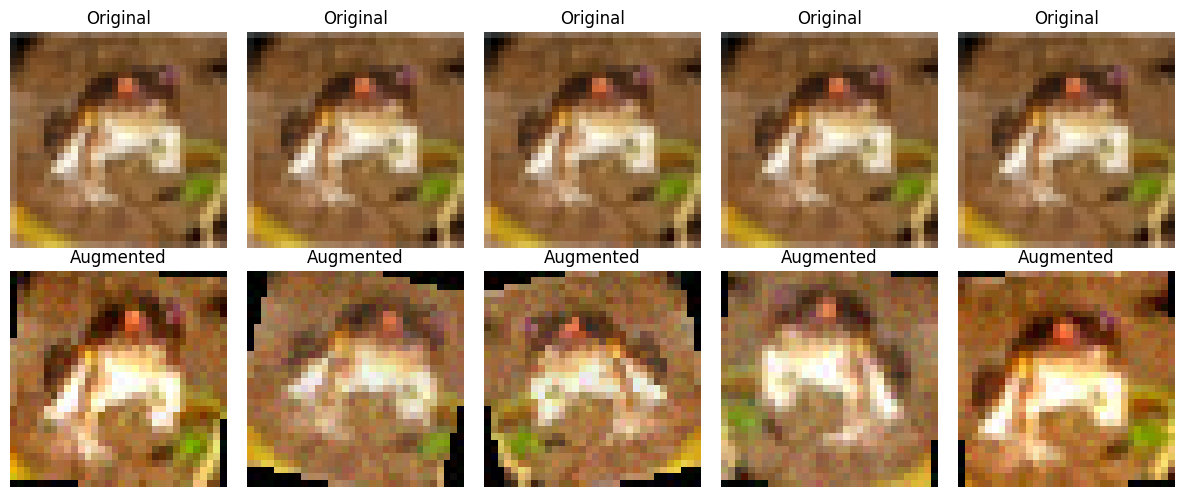

Training augmentation enabled; evaluation uses normalization only.


In [5]:
# Demonstrate ALL suggested transformations; normalization is shared with test data.
augment_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Lambda(lambda t: torch.clamp(t + 0.03*torch.randn_like(t), 0, 1)), # noise
    transforms.Normalize(MEAN, STD),
])
normalize_only = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

# Explicit ToPILImage example (the dataset itself provides PIL images if no transform is used)
example_tensor, example_label = train_raw[0]
example_pil = transforms.ToPILImage()(example_tensor)
print('ToPILImage conversion:', type(example_pil).__name__)

train_aug = datasets.CIFAR10(root=DATA_PATH, train=True, download=False, transform=augment_transform)
train_plain = datasets.CIFAR10(root=DATA_PATH, train=True, download=False, transform=normalize_only)
test_data = datasets.CIFAR10(root=DATA_PATH, train=False, download=False, transform=normalize_only)

def undo_normalize(t):
    mean = torch.tensor(MEAN).view(3,1,1)
    std = torch.tensor(STD).view(3,1,1)
    return (t.cpu()*std + mean).clamp(0,1).permute(1,2,0).numpy()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    axes[0,i].imshow(example_pil); axes[0,i].set_title('Original'); axes[0,i].axis('off')
    axes[1,i].imshow(undo_normalize(augment_transform(example_pil)))
    axes[1,i].set_title('Augmented'); axes[1,i].axis('off')
fig.tight_layout(); fig.savefig(OUT/'augmentation_examples.png', dpi=160); plt.show()

train_plain_loader = DataLoader(train_plain, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=='cuda'))
train_aug_loader = DataLoader(train_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=='cuda'))
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=='cuda'))
print('Training augmentation enabled; evaluation uses normalization only.')


## Task 5 — Train, tune hyperparameters, plot and compare results
Three full-dataset experiments: **baseline**, **augmentation**, **deeper model + tuned learning rate/batch size**. The test set is used for assignment evaluation only. For rigorous model selection, use a separate validation split.


===== Starting baseline =====
baseline | epoch 1/5 | train loss 1.4292 | test loss 1.1205 | test accuracy 60.15%
baseline | epoch 2/5 | train loss 1.0615 | test loss 0.9331 | test accuracy 67.26%
baseline | epoch 3/5 | train loss 0.9211 | test loss 0.8991 | test accuracy 68.41%
baseline | epoch 4/5 | train loss 0.8137 | test loss 0.8414 | test accuracy 70.54%
baseline | epoch 5/5 | train loss 0.7380 | test loss 0.8077 | test accuracy 71.91%


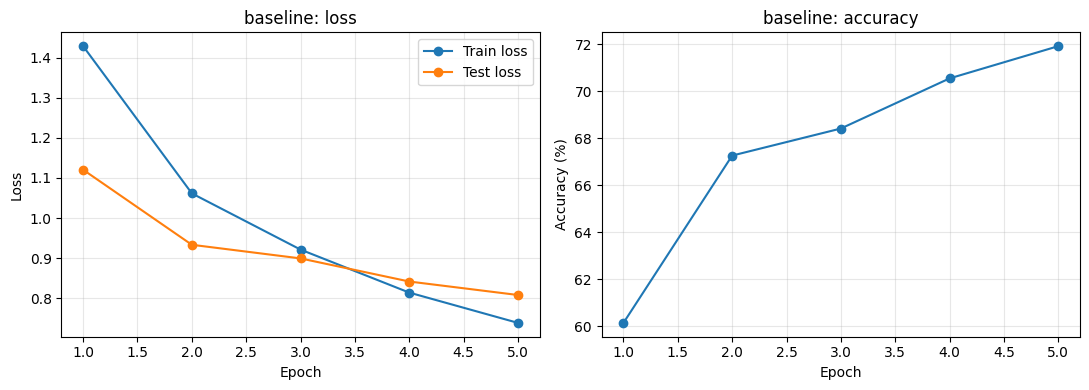


===== Starting augmented =====
augmented | epoch 1/5 | train loss 1.6213 | test loss 1.2665 | test accuracy 55.11%
augmented | epoch 2/5 | train loss 1.3559 | test loss 1.1083 | test accuracy 60.54%
augmented | epoch 3/5 | train loss 1.2425 | test loss 1.0245 | test accuracy 63.74%
augmented | epoch 4/5 | train loss 1.1817 | test loss 1.0091 | test accuracy 64.37%
augmented | epoch 5/5 | train loss 1.1387 | test loss 0.9252 | test accuracy 67.58%


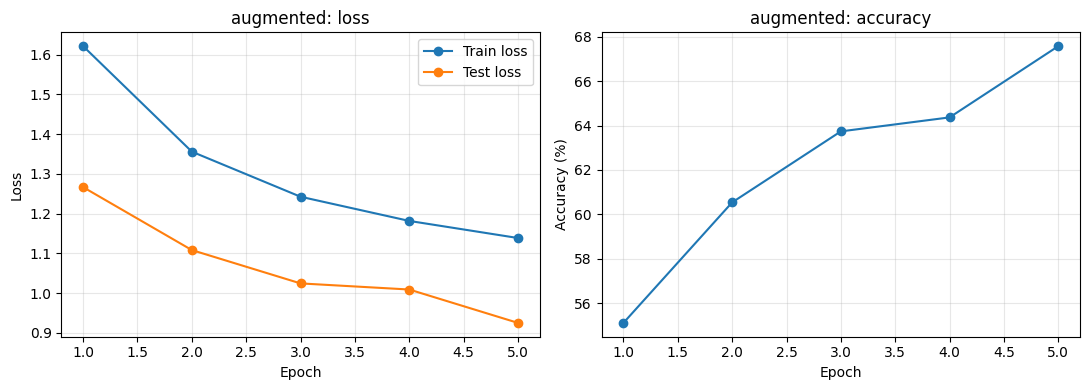


===== Starting tuned_deep =====
tuned_deep | epoch 1/5 | train loss 1.6242 | test loss 1.2971 | test accuracy 53.38%
tuned_deep | epoch 2/5 | train loss 1.2902 | test loss 1.1328 | test accuracy 59.53%
tuned_deep | epoch 3/5 | train loss 1.1664 | test loss 1.0864 | test accuracy 60.22%
tuned_deep | epoch 4/5 | train loss 1.0732 | test loss 0.9280 | test accuracy 66.96%
tuned_deep | epoch 5/5 | train loss 1.0143 | test loss 0.8572 | test accuracy 69.38%


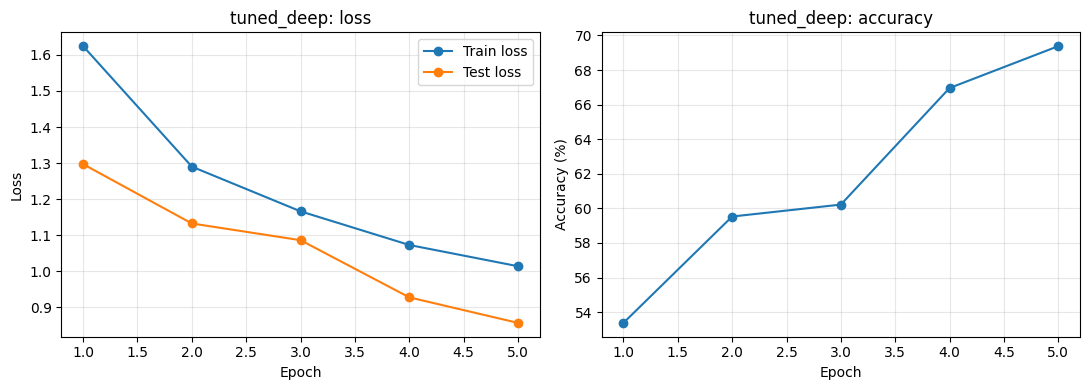

,experiment,learning_rate,batch_size,epochs,final_train_loss,final_test_loss,final_test_accuracy,best_test_accuracy,training_seconds
0,baseline,0.0010,128,5,0.738040,0.807670,71.91,71.91,69.0
1,augmented,0.0010,128,5,1.138666,0.925152,67.58,67.58,215.3
2,tuned_deep,0.0005,128,5,1.014306,0.857250,69.38,69.38,211.3


In [6]:
def fit_experiment(name, model, train_loader, lr, epochs):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = []
    start = time.perf_counter()
    best_accuracy = -1.0
    for epoch in range(1, epochs+1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        test_loss, test_acc = evaluate(model, test_loader, criterion)
        history.append({'epoch': epoch, 'train_loss':train_loss, 'train_accuracy':train_acc,
                        'test_loss':test_loss, 'test_accuracy':test_acc})
        print(f'{name} | epoch {epoch}/{epochs} | train loss {train_loss:.4f} | '
              f'test loss {test_loss:.4f} | test accuracy {test_acc:.2f}%')
        if test_acc > best_accuracy:
            best_accuracy = test_acc
            torch.save(model.state_dict(), OUT/f'{name}_best.pt')
    elapsed = time.perf_counter()-start
    df = pd.DataFrame(history)
    df.to_csv(OUT/f'{name}_history.csv', index=False)
    fig, ax = plt.subplots(1, 2, figsize=(11,4))
    ax[0].plot(df.epoch, df.train_loss, marker='o', label='Train loss')
    ax[0].plot(df.epoch, df.test_loss, marker='o', label='Test loss')
    ax[0].set(title=f'{name}: loss', xlabel='Epoch', ylabel='Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(df.epoch, df.test_accuracy, marker='o', label='Test accuracy')
    ax[1].set(title=f'{name}: accuracy', xlabel='Epoch', ylabel='Accuracy (%)'); ax[1].grid(alpha=.3)
    fig.tight_layout(); fig.savefig(OUT/f'{name}_curves.png', dpi=160); plt.show(); plt.close(fig)
    return {'experiment':name, 'learning_rate':lr, 'batch_size':train_loader.batch_size,
            'epochs': epochs, 'final_train_loss':df.train_loss.iloc[-1],
            'final_test_loss':df.test_loss.iloc[-1],
            'final_test_accuracy':df.test_accuracy.iloc[-1],
            'best_test_accuracy':df.test_accuracy.max(), 'training_seconds':round(elapsed,1)}

# Full training on CIFAR-10: this cell can take several minutes on a Colab GPU.
experiments = [
    ('baseline', SmallCNN(), train_plain_loader, 0.001),
    ('augmented', SmallCNN(), train_aug_loader, 0.001),
    ('tuned_deep', DeepCNN(), train_aug_loader, 0.0005),
]
results = []
for name, model, loader, lr in experiments:
    print('\n===== Starting', name, '=====')
    results.append(fit_experiment(name, model, loader, lr, EPOCHS))
summary = pd.DataFrame(results)
summary.to_csv(OUT/'comparison.csv', index=False)
display(summary)


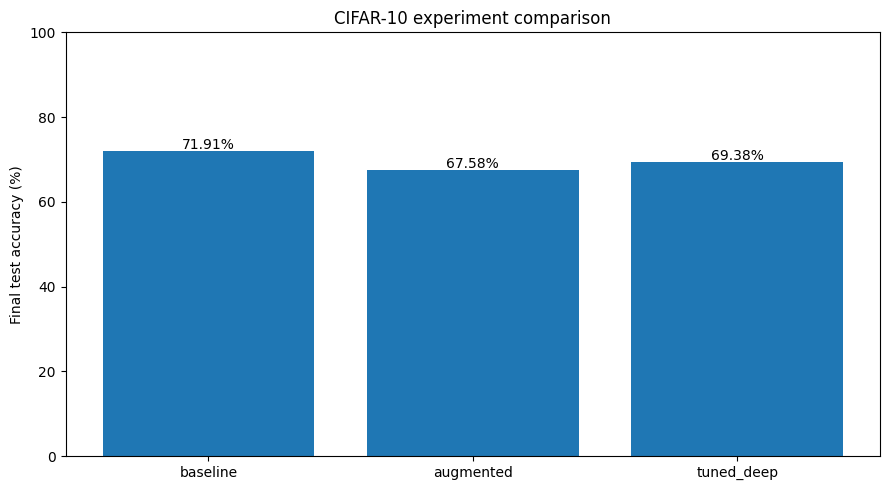

Highest final test accuracy: baseline
All results are actual measurements produced in this runtime.


In [7]:
# Compare accuracy and losses across architectures/augmentations
fig, ax = plt.subplots(figsize=(9,5))
ax.bar(summary.experiment, summary.final_test_accuracy)
ax.set(ylabel='Final test accuracy (%)', title='CIFAR-10 experiment comparison')
for i, value in enumerate(summary.final_test_accuracy): ax.text(i, value+0.5, f'{value:.2f}%', ha='center')
ax.set_ylim(0, max(100, summary.final_test_accuracy.max()+7))
fig.tight_layout(); fig.savefig(OUT/'comparison_accuracy.png', dpi=160); plt.show()
print('Highest final test accuracy:', summary.loc[summary.final_test_accuracy.idxmax(),'experiment'])
print('All results are actual measurements produced in this runtime.')


baseline_batch64 | epoch 1/5 | train loss 1.3926 | test loss 1.0854 | test accuracy 61.15%
baseline_batch64 | epoch 2/5 | train loss 1.0426 | test loss 0.9498 | test accuracy 66.47%
baseline_batch64 | epoch 3/5 | train loss 0.9108 | test loss 0.8772 | test accuracy 69.40%
baseline_batch64 | epoch 4/5 | train loss 0.8132 | test loss 0.8510 | test accuracy 70.05%
baseline_batch64 | epoch 5/5 | train loss 0.7306 | test loss 0.8156 | test accuracy 72.04%


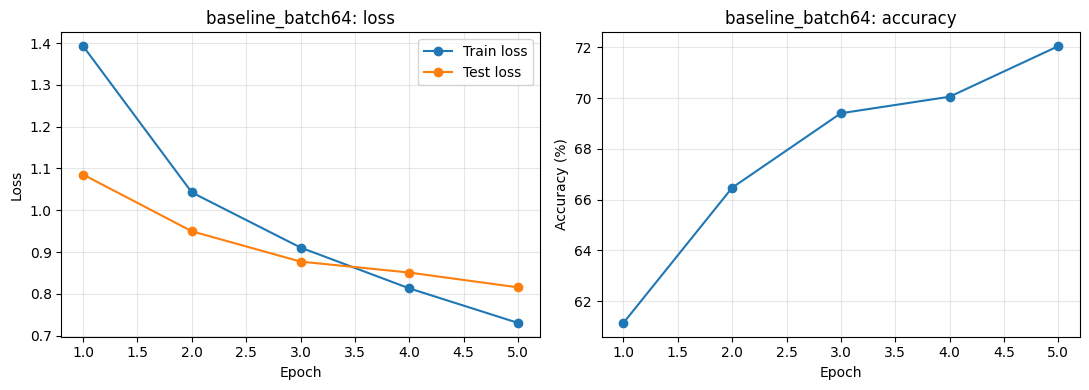

,experiment,learning_rate,batch_size,epochs,final_train_loss,final_test_loss,final_test_accuracy,best_test_accuracy,training_seconds
0,baseline,0.0010,128,5,0.738040,0.807670,71.91,71.91,69.0
1,augmented,0.0010,128,5,1.138666,0.925152,67.58,67.58,215.3
2,tuned_deep,0.0005,128,5,1.014306,0.857250,69.38,69.38,211.3
3,baseline_batch64,0.0010,64,5,0.730629,0.815621,72.04,72.04,78.5


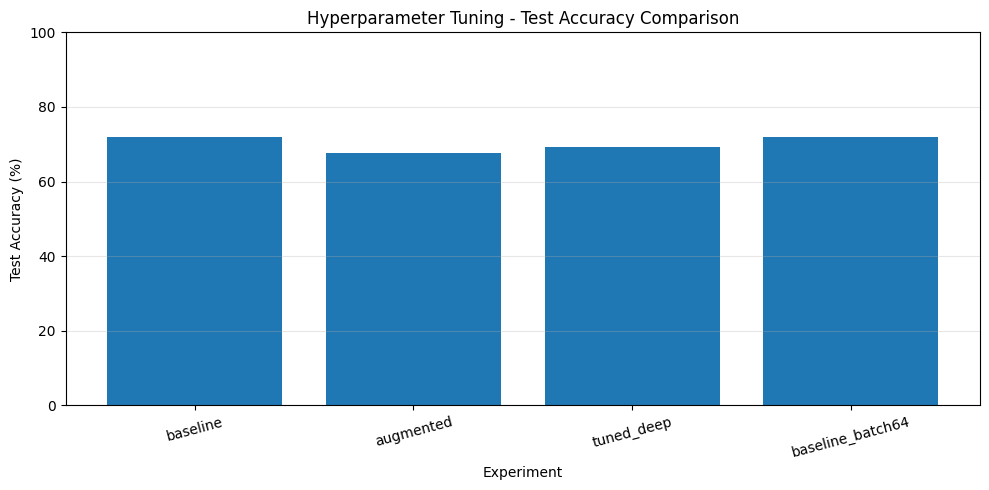

Best experiment:
experiment             baseline_batch64
learning_rate                     0.001
batch_size                           64
epochs                                5
final_train_loss               0.730629
final_test_loss                0.815621
final_test_accuracy               72.04
best_test_accuracy                72.04
training_seconds                   78.5
Name: 3, dtype: object


In [8]:

# Experiment: Changing Batch Size from 128 to 64

BATCH_SIZE_NEW = 64

train_loader_64 = DataLoader(
    train_plain,
    batch_size=BATCH_SIZE_NEW,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == 'cuda')
)

# Train with the new batch size
new_result = fit_experiment(
    name='baseline_batch64',
    model=SmallCNN(),
    train_loader=train_loader_64,
    lr=0.001,
    epochs=EPOCHS
)

# Add the new experiment to the previous results
summary = pd.concat(
    [summary, pd.DataFrame([new_result])],
    ignore_index=True
)

# Display comparison
display(summary)

# Plot test accuracy comparison
plt.figure(figsize=(10, 5))
plt.bar(
    summary['experiment'],
    summary['final_test_accuracy']
)

plt.title('Hyperparameter Tuning - Test Accuracy Comparison')
plt.xlabel('Experiment')
plt.ylabel('Test Accuracy (%)')
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Save updated results
summary.to_csv(OUT / 'comparison.csv', index=False)

print("Best experiment:")
print(summary.loc[summary['final_test_accuracy'].idxmax()])
